# Hierarchical Document Index (hindex) Visualizer

Explore the topic-based document hierarchies built by **hindex** — Colette's vision-first hierarchical indexing strategy.  Reads directly from the on-disk JSON files and the HDF5 image kvstore.  No service initialization required.

Covers:

1. **Setup** — imports and path configuration
2. **Load Hierarchies** — parse all JSON files from the hindex directory
3. **Overview Statistics** — per-document summary table
4. **Topic Structure** — interactive sunburst and treemap charts
5. **Page × Topic Membership Heatmap** — which pages belong to which topics
6. **Per-Page Data Table** — DataFrame of all page records + word count histograms
7. **Keyword Analysis** — top keywords across the corpus and per topic
8. **Page Images with Extracted Metadata** — browse actual page images with metadata
9. **Cross-Document Comparison** — radar chart (requires ≥ 2 documents)
10. **Export** — CSV export and text tree dump

## 1. Setup

In [1]:
# Uncomment to install missing packages
# !pip install plotly pandas pillow h5py

In [2]:
import json
import os
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from PIL import Image
import h5py

print("Packages loaded.")

Packages loaded.


In [3]:
# ── Path configuration ────────────────────────────────────────────────────────
# Notebook lives in examples/ so the repo root is one level up
colette_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Change app_dir to match your Colette application directory
app_dir = Path(colette_root) / "app_colette"

hindex_dir = app_dir / "mm_index" / "hindex"
kvstore_path = app_dir / "kvstore.db"

print(f"colette_root : {colette_root}")
print(f"app_dir      : {app_dir}")
print(f"hindex_dir   : {hindex_dir}")
print(f"  exists     : {hindex_dir.exists()}")
print(f"kvstore_path : {kvstore_path}")
print(f"  exists     : {kvstore_path.exists()}")

colette_root : /data1/ldejesus/repos/public/colette
app_dir      : /data1/ldejesus/repos/public/colette/app_colette
hindex_dir   : /data1/ldejesus/repos/public/colette/app_colette/mm_index/hindex
  exists     : True
kvstore_path : /data1/ldejesus/repos/public/colette/app_colette/kvstore.db
  exists     : True


## 2. Load Hierarchies

In [4]:
sys.path.insert(0, os.path.join(colette_root, "src"))
from colette.backends.hf.hindex import DocumentHierarchy, PageRecord, TopicNode

hierarchies = []

if not hindex_dir.exists():
    print(f"WARNING: hindex directory not found: {hindex_dir}")
    print("Run the indexing pipeline first to generate hindex JSON files.")
else:
    json_files = sorted(hindex_dir.glob("*.json"))
    if not json_files:
        print(f"WARNING: No JSON files found in {hindex_dir}")
    else:
        for p in json_files:
            try:
                data = json.loads(p.read_text(encoding="utf-8"))
                h = DocumentHierarchy.from_dict(data)
                hierarchies.append(h)
                print(
                    f"  Loaded: {p.name}"
                    f"  |  pages={h.page_count}"
                    f"  |  topics={len(h.topics)}"
                    f"  |  page_records={len(h.page_records)}"
                )
            except Exception as exc:
                print(f"  WARNING: could not load {p.name}: {exc}")

print(f"\nTotal hierarchies loaded: {len(hierarchies)}")

  Loaded: _data1_ldejesus_repos_public_colette_docs_pdf_COLETTEv2_Restitution_2025_03_07_v0_3_JB_light_pdf.json  |  pages=16  |  topics=8  |  page_records=16

Total hierarchies loaded: 1


## 3. Overview Statistics

One row per document with aggregated metrics about pages, topics, keywords, summaries, and crops.

In [5]:
def _overview_row(h):
    pr = h.page_records
    topics = h.topics

    # Mean pages per topic
    pages_per_topic = (
        np.mean([len(t.page_indices) for t in topics]) if topics else float("nan")
    )

    # Pages that appear in more than one topic
    from collections import Counter as _Counter
    page_topic_count = _Counter(p for t in topics for p in t.page_indices)
    multi_topic_pages = sum(1 for cnt in page_topic_count.values() if cnt > 1)

    avg_kw = np.mean([len(r.keywords) for r in pr]) if pr else float("nan")
    avg_summary_words = (
        np.mean([len(r.summary.split()) for r in pr]) if pr else float("nan")
    )
    total_crops = sum(len(r.crop_keys) for r in pr)

    return {
        "Document": Path(h.doc_name).name,
        "Pages": h.page_count,
        "Topics": len(topics),
        "Pages/topic": round(pages_per_topic, 1),
        "Multi-topic pages": multi_topic_pages,
        "Avg keywords/page": round(avg_kw, 1),
        "Avg summary words": round(avg_summary_words, 1),
        "Total crops": total_crops,
    }

if not hierarchies:
    print("No hierarchies loaded — skipping statistics table.")
else:
    df_overview = pd.DataFrame([_overview_row(h) for h in hierarchies])
    display(df_overview)

,Document,Pages,Topics,Pages/topic,Multi-topic pages,Avg keywords/page,Avg summary words,Total crops
0,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,16,8,2.0,0,5.5,25.2,45


## 4. Topic Structure — Sunburst & Treemap

Each ring / tile represents one level:
- **Centre** = document
- **Level 1** = topics (sized by number of pages)
- **Level 2** = individual pages (`p{page_idx}`, each counts as 1)

Because a page can belong to multiple topics each page node gets a unique ID `{doc}::{topic_id}::p{page_idx}` to prevent Plotly from merging them.

In [6]:
def _build_chart_data(h):
    ids, labels, parents, values, hover = [], [], [], [], []

    root_id = h.doc_name
    # With branchvalues="total", root value must equal sum of direct children.
    # Pages can belong to multiple topics so topic slot count may exceed page_count.
    root_value = sum(len(t.page_indices) for t in h.topics) if h.topics else h.page_count

    ids.append(root_id)
    labels.append(Path(h.doc_name).name)
    parents.append("")
    values.append(root_value)
    hover.append(h.doc_description or h.doc_name)

    for t in h.topics:
        t_id = f"{root_id}::{t.topic_id}"
        ids.append(t_id)
        labels.append(t.theme)
        parents.append(root_id)
        values.append(len(t.page_indices))
        kw_str = ", ".join(t.keywords) if t.keywords else "—"
        hover.append(f"{t.theme}<br>{t.description}<br>Keywords: {kw_str}")

        for page_idx in t.page_indices:
            p_id = f"{root_id}::{t.topic_id}::p{page_idx}"
            ids.append(p_id)
            labels.append(f"p{page_idx}")
            parents.append(t_id)
            values.append(1)
            rec = h.record_for_page(page_idx)
            summary = rec.summary[:120] if rec and rec.summary else "(no summary)"
            hover.append(f"Page {page_idx}<br>{summary}")

    return ids, labels, parents, values, hover


if not hierarchies:
    print("No hierarchies loaded — skipping topic charts.")
else:
    for h in hierarchies:
        if not h.topics:
            print(f"  {Path(h.doc_name).name}: no topics (old-format file), skipping chart.")
            continue

        ids, labels, parents, values, hover = _build_chart_data(h)

        fig = go.Figure(go.Sunburst(
            ids=ids,
            labels=labels,
            parents=parents,
            values=values,
            customdata=hover,
            hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>",
            branchvalues="total",
            maxdepth=3,
        ))
        fig.update_layout(
            title=f"Topic Structure (Sunburst) — {Path(h.doc_name).name}",
            width=700,
            height=700,
        )
        fig.show(renderer="notebook_connected")

In [7]:
if hierarchies:
    for h in hierarchies:
        if not h.topics:
            continue

        ids, labels, parents, values, hover = _build_chart_data(h)

        fig = go.Figure(go.Treemap(
            ids=ids,
            labels=labels,
            parents=parents,
            values=values,
            customdata=hover,
            hovertemplate="<b>%{label}</b><br>%{customdata}<extra></extra>",
            branchvalues="total",
            maxdepth=3,
        ))
        fig.update_layout(
            title=f"Topic Structure (Treemap) — {Path(h.doc_name).name}",
            width=900,
            height=500,
        )
        fig.show(renderer="notebook_connected")

## 5. Page × Topic Membership Heatmap

Each cell is 1 (blue) if the page belongs to that topic, 0 (white) if not.  The title reports how many pages appear in more than one topic.

In [8]:
if not hierarchies:
    print("No hierarchies loaded — skipping heatmap.")
else:
    for h in hierarchies:
        if not h.topics:
            print(f"  {Path(h.doc_name).name}: no topics, skipping heatmap.")
            continue

        n_pages = h.page_count
        topic_themes = [t.theme for t in h.topics]

        # Build membership matrix: rows = pages, cols = topics
        matrix = np.zeros((n_pages, len(h.topics)), dtype=int)
        for col_idx, t in enumerate(h.topics):
            for p in t.page_indices:
                if 0 <= p < n_pages:
                    matrix[p, col_idx] = 1

        multi_count = int((matrix.sum(axis=1) > 1).sum())

        fig = px.imshow(
            matrix,
            x=topic_themes,
            y=[f"p{i}" for i in range(n_pages)],
            color_continuous_scale=[[0, "white"], [1, "steelblue"]],
            zmin=0,
            zmax=1,
            labels={"x": "Topic", "y": "Page", "color": "Member"},
            title=(
                f"Page × Topic Membership — {Path(h.doc_name).name}"
                f"  ({multi_count} page(s) in multiple topics)"
            ),
            aspect="auto",
        )
        fig.update_layout(height=max(300, n_pages * 20 + 120))
        fig.show(renderer="notebook_connected")

## 6. Per-Page Data Table

All `PageRecord` fields in a pandas DataFrame, plus derived columns for quick inspection.  Followed by word-count distribution histograms.

In [9]:
all_page_rows = []
for h in hierarchies:
    if not h.page_records:
        print(f"  {Path(h.doc_name).name}: no page_records (old-format file), skipping.")
        continue
    for r in h.page_records:
        all_page_rows.append({
            "document": Path(h.doc_name).name,
            "page_idx": r.page_idx,
            "summary": (r.summary[:100] + "…") if len(r.summary) > 100 else r.summary,
            "keywords": "; ".join(r.keywords),
            "summary_words": len(r.summary.split()),
            "text_words": len(r.text_content.split()),
            "has_visual": bool(r.visual_description),
            "n_crops": len(r.crop_keys),
        })

if not all_page_rows:
    print("No page_records found across any loaded hierarchy.")
else:
    df_pages = pd.DataFrame(all_page_rows)
    display(df_pages)

,document,page_idx,summary,keywords,summary_words,text_words,has_visual,n_crops
0,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,0,This is the opening slide of a presentation in...,Colette; GenAI; CNES; Airbus; présentation,23,14,True,3
1,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,1,This page outlines the general description of ...,Colette; RAG; LLM; vision; Open Source,19,30,True,4
2,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,2,"This page details Colette's RAG approach, incl...",RAG; LLM; fine-tuning; NeurIPS 2020; apprentis...,21,35,True,1
3,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,3,"This page presents Colette in application, hig...",Colette; application; défis; RAG; LLM,16,23,True,4
4,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,4,"This page introduces the COLETTE project, focu...",COLETTE; OCR; LLM; document processing; automa...,28,41,True,3
5,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,5,This page details the objectives of the COLETT...,COLETTE; VLLM; image processing; neural networ...,31,34,True,1
6,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,6,This page explores the challenges and solution...,COLETTE; error handling; VLLM; document proces...,30,36,True,4
7,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,7,This page provides a detailed view of the COLE...,COLETTE; Vision-RAG; indexing; document types;...,34,36,True,3
8,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,8,This page outlines the training process of the...,Colette; training; VLLM; embedding; generator;...,34,19,True,4
9,COLETTEv2_Restitution_2025_03_07_v0.3_JB_light...,9,This page describes the architecture of the Co...,Colette; architecture; REST API; Colette Serve...,35,20,True,1


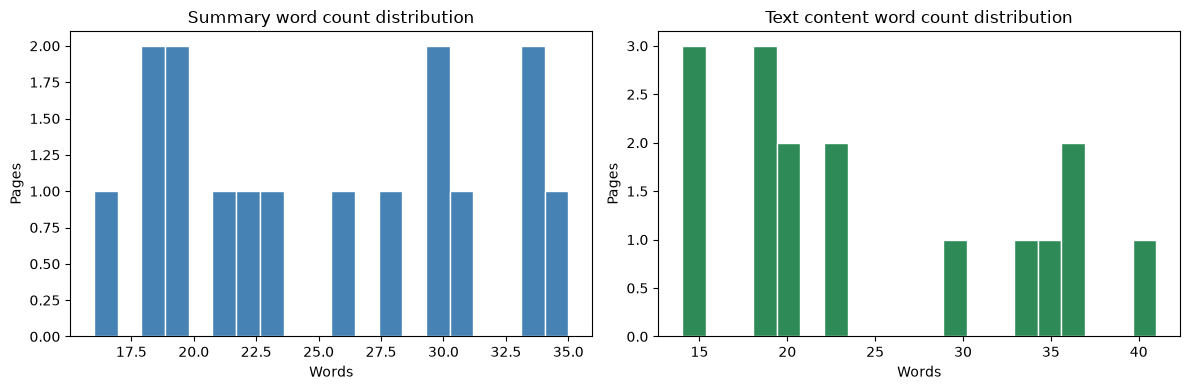

In [10]:
if all_page_rows:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.hist(df_pages["summary_words"], bins=20, color="steelblue", edgecolor="white")
    ax1.set_xlabel("Words")
    ax1.set_ylabel("Pages")
    ax1.set_title("Summary word count distribution")

    ax2.hist(df_pages["text_words"], bins=20, color="seagreen", edgecolor="white")
    ax2.set_xlabel("Words")
    ax2.set_ylabel("Pages")
    ax2.set_title("Text content word count distribution")

    plt.tight_layout()
    plt.show()

## 7. Keyword Analysis

Top-20 most frequent keywords across all `PageRecord`s (combined), then per-document keyword frequency from the `TopicNode` keywords.

In [11]:
# Global top-20 page-level keywords
all_page_keywords = []
for h in hierarchies:
    for r in h.page_records:
        all_page_keywords.extend(r.keywords)

if not all_page_keywords:
    print("No page-level keywords found.")
else:
    kw_counts = Counter(all_page_keywords)
    top20 = kw_counts.most_common(20)
    kw_df = pd.DataFrame(top20, columns=["keyword", "count"])

    fig = px.bar(
        kw_df,
        x="count",
        y="keyword",
        orientation="h",
        title="Top-20 Keywords Across All Page Records",
        labels={"count": "Occurrences", "keyword": "Keyword"},
        color="count",
        color_continuous_scale="Blues",
    )
    fig.update_layout(yaxis={"categoryorder": "total ascending"}, height=500)
    fig.show(renderer="notebook_connected")

In [12]:
# Per-document topic keyword frequency
for h in hierarchies:
    if not h.topics:
        continue

    topic_kw_rows = []
    for t in h.topics:
        for kw in t.keywords:
            topic_kw_rows.append({"topic": t.theme, "keyword": kw})

    if not topic_kw_rows:
        continue

    df_tkw = pd.DataFrame(topic_kw_rows)
    kw_freq = df_tkw.groupby("keyword").size().reset_index(name="count").sort_values("count", ascending=False)

    fig = px.bar(
        kw_freq.head(15),
        x="count",
        y="keyword",
        orientation="h",
        title=f"Topic Keyword Frequency — {Path(h.doc_name).name}",
        labels={"count": "Occurrences", "keyword": "Keyword"},
        color="count",
        color_continuous_scale="Purples",
    )
    fig.update_layout(yaxis={"categoryorder": "total ascending"}, height=400)
    fig.show(renderer="notebook_connected")

## 8. Page Images with Extracted Metadata

Browse actual page images from the kvstore alongside the structured metadata that hindex extracted.  Configure the cells below to pick a document, topic, and page limit.

In [13]:
# ── Configuration ────────────────────────────────────────────────────────────────
TARGET_DOC_INDEX = 0    # index into the `hierarchies` list
TARGET_TOPIC_ID  = None  # e.g. "T01"; None → use the first available topic
MAX_PAGES        = 3    # maximum number of pages to display
SHOW_CROPS       = False  # if True, also display individual crop images below each page

Document : /data1/ldejesus/repos/public/colette/docs/pdf/COLETTEv2_Restitution_2025_03_07_v0.3_JB_light.pdf
Topic    : [T01] System Architecture & Components
Pages    : [9, 11]
kvstore  : /data1/ldejesus/repos/public/colette/app_colette/kvstore.db


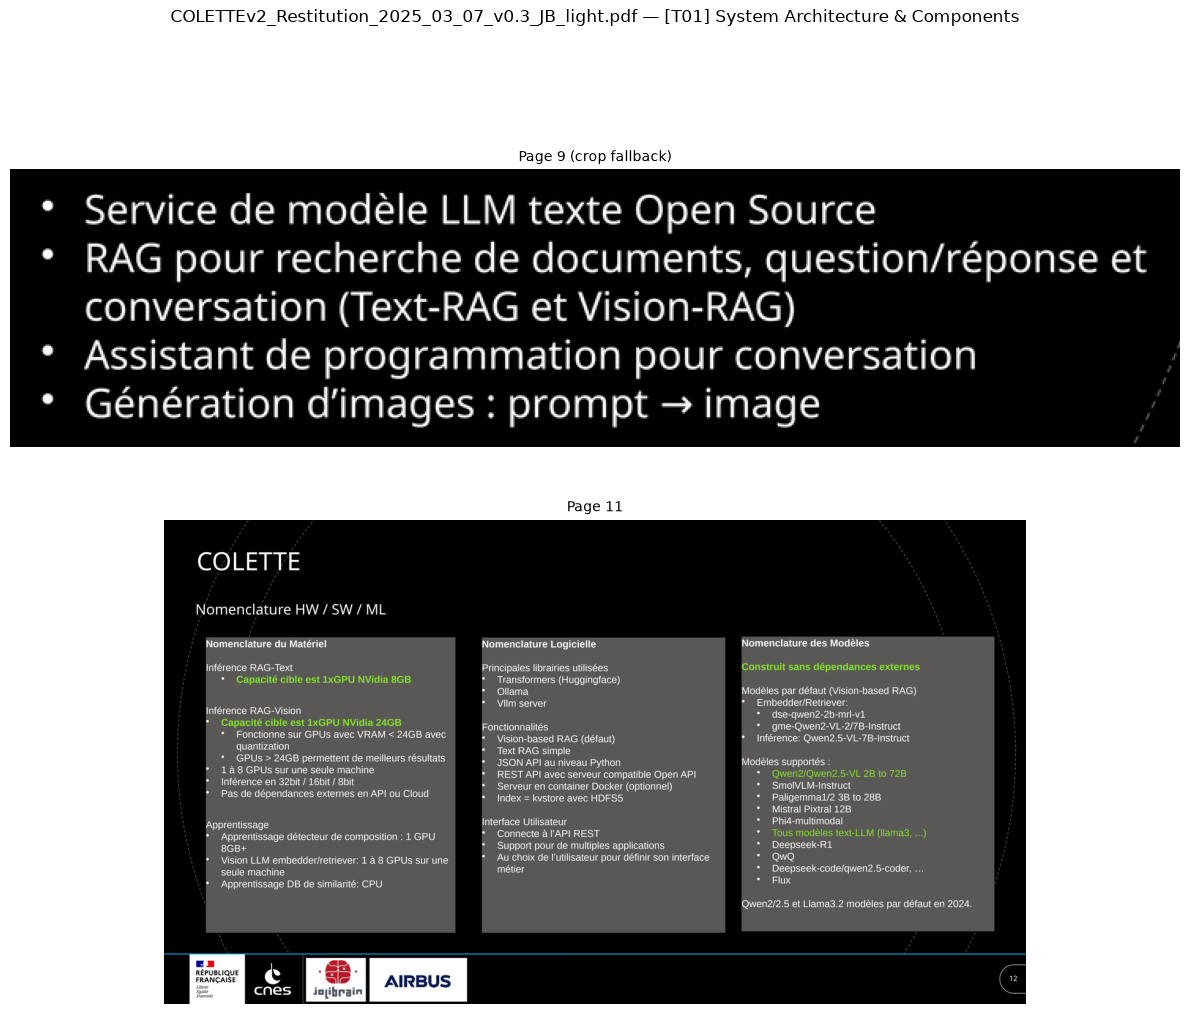

────────────────────────────────────────────────────────────
Page 9
  Summary  : This page describes the architecture of the Colette system, detailing the interaction between the Colette UI and the Colette Server. It highlights the use of REST API for communication and the components within the server.
  Keywords : Colette, architecture, REST API, Colette Server, LLM, RAG
  Visual   : Architecture diagram showing Colette UI connected to Colette Server via REST API. Server includes components like 'Colette Server', 'LLM', 'RAG', and 'LLM'.
  Text     : Architecture : Serveur Multi-applications / RAGs, Modèles partagés (optionnel), Modèles externalisés (optionnel), UE de demande (recherche interne, pas de dépendance).
────────────────────────────────────────────────────────────
Page 11
  Summary  : This page provides a nomenclature for various components used in the Colette system, categorized into hardware, software, and models. It lists specific items and their descriptions.
  Keywords

In [14]:
from colette.kvstore import HDF5ImageStorage

if not hierarchies:
    print("No hierarchies loaded.")
elif TARGET_DOC_INDEX >= len(hierarchies):
    print(f"TARGET_DOC_INDEX {TARGET_DOC_INDEX} out of range (only {len(hierarchies)} loaded).")
else:
    h = hierarchies[TARGET_DOC_INDEX]

    # Resolve the target topic
    if not h.topics:
        print(f"WARNING: {Path(h.doc_name).name} has no topics (old-format file).")
        target_topic = None
    elif TARGET_TOPIC_ID is None:
        target_topic = h.topics[0]
    else:
        target_topic = next((t for t in h.topics if t.topic_id == TARGET_TOPIC_ID), h.topics[0])

    if target_topic is None:
        print("No topic found — cannot display pages.")
    elif not kvstore_path.exists():
        print(f"kvstore not found at {kvstore_path}")
        print("Run the indexing pipeline first to populate the kvstore.")
    else:
        print(f"Document : {h.doc_name}")
        print(f"Topic    : [{target_topic.topic_id}] {target_topic.theme}")
        print(f"Pages    : {target_topic.page_indices}")
        print(f"kvstore  : {kvstore_path}")

        # Select pages (up to MAX_PAGES)
        page_indices = target_topic.page_indices[:MAX_PAGES]
        n_pages = len(page_indices)

        kvstore = HDF5ImageStorage(kvstore_path, mode="r")
        loaded = []
        missing = []

        for page_idx in page_indices:
            # Determine the kvstore key for the full-page image
            if page_idx < len(h.page_keys) and h.page_keys[page_idx]:
                page_key = h.page_keys[page_idx]
            else:
                # Fall back to page_record.page_key if available
                rec = h.record_for_page(page_idx)
                page_key = rec.page_key if rec else ""

            if not page_key:
                missing.append(page_idx)
                continue

            # Try full-page key, then first crop key as fallback
            resolved_key = page_key
            if not kvstore.has_key(resolved_key):
                resolved_key = f"{page_key}_crop_0000"

            try:
                img = kvstore.retrieve_image(resolved_key)
                rec = h.record_for_page(page_idx)
                loaded.append((page_idx, img, resolved_key, rec))
            except KeyError:
                missing.append(page_idx)

        kvstore.close()

        if missing:
            print(f"Pages not found in kvstore (skipped): {missing}")

        # Display pages + metadata
        fig_height = n_pages * 5
        fig, axes = plt.subplots(n_pages, 1, figsize=(12, fig_height)) if n_pages > 1 else plt.subplots(figsize=(12, 5))
        axes_list = [axes] if n_pages == 1 else list(axes)

        for ax, (page_idx, img, rkey, rec) in zip(axes_list, loaded):
            ax.imshow(img)
            ax.axis("off")
            suffix = " (crop fallback)" if "_crop_" in rkey else ""
            ax.set_title(f"Page {page_idx}{suffix}", fontsize=10, pad=6)

        plt.suptitle(
            f"{Path(h.doc_name).name} — [{target_topic.topic_id}] {target_topic.theme}",
            fontsize=12,
            y=1.01,
        )
        plt.tight_layout()
        plt.show()

        # Print metadata below the figure
        for page_idx, img, rkey, rec in loaded:
            print(f"{'─' * 60}")
            print(f"Page {page_idx}")
            if rec:
                print(f"  Summary  : {rec.summary}")
                print(f"  Keywords : {', '.join(rec.keywords)}")
                if rec.visual_description:
                    print(f"  Visual   : {rec.visual_description}")
                if rec.text_content:
                    snippet = rec.text_content[:200]
                    print(f"  Text     : {snippet}{'…' if len(rec.text_content) > 200 else ''}")
            else:
                print("  (no PageRecord found for this page)")

        # Optionally show crop images
        if SHOW_CROPS:
            kvstore = HDF5ImageStorage(kvstore_path, mode="r")
            for page_idx, img, rkey, rec in loaded:
                if rec is None or not rec.crop_keys:
                    continue
                n_crops = len(rec.crop_keys)
                fig_c, axes_c = plt.subplots(1, n_crops, figsize=(4 * n_crops, 4))
                axes_c_list = [axes_c] if n_crops == 1 else list(axes_c)
                for cax, ck in zip(axes_c_list, rec.crop_keys):
                    try:
                        cimg = kvstore.retrieve_image(ck)
                        cax.imshow(cimg)
                    except KeyError:
                        cax.text(0.5, 0.5, "missing", ha="center", va="center", transform=cax.transAxes)
                    cax.axis("off")
                    cax.set_title(ck, fontsize=7)
                plt.suptitle(f"Crops — Page {page_idx}", fontsize=10)
                plt.tight_layout()
                plt.show()
            kvstore.close()

## 9. Cross-Document Comparison

Radar chart comparing structural metrics across all indexed documents.  Requires at least 2 documents.

In [15]:
def _doc_stats(h):
    pr = h.page_records
    topics = h.topics

    avg_kw = float(np.mean([len(r.keywords) for r in pr])) if pr else 0.0
    avg_summary_words = float(np.mean([len(r.summary.split()) for r in pr])) if pr else 0.0
    avg_crops = float(np.mean([len(r.crop_keys) for r in pr])) if pr else 0.0

    from collections import Counter as _C
    page_topic_count = _C(p for t in topics for p in t.page_indices)
    multi_pct = (
        100.0 * sum(1 for v in page_topic_count.values() if v > 1) / h.page_count
        if h.page_count else 0.0
    )

    return {
        "name": Path(h.doc_name).name,
        "page_count": h.page_count,
        "n_topics": len(topics),
        "avg_keywords_per_page": round(avg_kw, 2),
        "avg_summary_words": round(avg_summary_words, 2),
        "avg_crops_per_page": round(avg_crops, 2),
        "multi_topic_pages_pct": round(multi_pct, 2),
    }

if not hierarchies:
    print("No hierarchies loaded.")
elif len(hierarchies) == 1:
    # Single-document: show metrics as a horizontal bar chart
    stats = _doc_stats(hierarchies[0])
    metric_labels = [
        "Pages", "Topics", "Avg keywords/page",
        "Avg summary words", "Avg crops/page", "Multi-topic pages %",
    ]
    metric_values = [
        stats["page_count"], stats["n_topics"], stats["avg_keywords_per_page"],
        stats["avg_summary_words"], stats["avg_crops_per_page"], stats["multi_topic_pages_pct"],
    ]
    fig = go.Figure(go.Bar(
        x=metric_values,
        y=metric_labels,
        orientation="h",
        marker_color="steelblue",
        text=[str(v) for v in metric_values],
        textposition="outside",
    ))
    fig.update_layout(
        title=f"Document Metrics — {stats['name']}",
        xaxis_title="Value",
        height=350,
        margin=dict(l=200),
    )
    fig.show(renderer="notebook_connected")
    print("\nLoad 2+ documents to see the cross-document radar chart.")
else:
    stats = [_doc_stats(h) for h in hierarchies]
    df_cmp = pd.DataFrame(stats).set_index("name")
    display(df_cmp)

    # Normalize columns to [0, 1] for the radar chart
    df_norm = (df_cmp - df_cmp.min()) / (df_cmp.max() - df_cmp.min() + 1e-9)
    categories = list(df_norm.columns)

    fig = go.Figure()
    for doc_name in df_norm.index:
        vals = df_norm.loc[doc_name].tolist()
        fig.add_trace(go.Scatterpolar(
            r=vals + [vals[0]],
            theta=categories + [categories[0]],
            fill="toself",
            name=doc_name,
        ))

    fig.update_layout(
        polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
        title="Cross-Document Comparison (normalized per metric)",
        height=520,
    )
    fig.show(renderer="notebook_connected")


Load 2+ documents to see the cross-document radar chart.


## 10. Export

Export all page records to a CSV file and print the compact text tree for each document.

In [16]:
export_rows = []
for h in hierarchies:
    for r in h.page_records:
        export_rows.append({
            "document": h.doc_name,
            "page_idx": r.page_idx,
            "page_key": r.page_key,
            "summary": r.summary,
            "keywords": ";".join(r.keywords),
            "summary_words": len(r.summary.split()),
            "text_words": len(r.text_content.split()),
            "has_visual": bool(r.visual_description),
            "visual_description": r.visual_description,
            "n_crops": len(r.crop_keys),
            "crop_keys": ";".join(r.crop_keys),
        })

if export_rows:
    df_export = pd.DataFrame(export_rows)
    out_path = Path("hindex_page_records.csv")
    df_export.to_csv(out_path, index=False)
    print(f"Saved {len(df_export)} rows to {out_path.resolve()}")
else:
    print("No page records to export.")

Saved 16 rows to /data1/ldejesus/repos/public/colette/examples/hindex_page_records.csv


In [17]:
# Print the compact text tree for each document
for h in hierarchies:
    print("=" * 70)
    print(h.as_text_tree())
    print()

Document: /data1/ldejesus/repos/public/colette/docs/pdf/COLETTEv2_Restitution_2025_03_07_v0.3_JB_light.pdf (16 pages)
  This document presents the Colette system, an open-source, domain-specific GenAI solution designed to automate document processing and enhance retrieval-augmented generation (RAG) capabilities through advanced AI techniques like VLLM and joint learning.

Topics:
  [T01] System Architecture & Components  (pages: 9, 11)
       Covers the high-level design, server-client interaction, and core component definitions of the Colette system.
  [T02] RAG Implementation & Training  (pages: 1, 2, 8)
       Details the Retrieval-Augmented Generation approach, including fine-tuning, joint learning, and model training processes.
  [T03] Document Processing Pipeline  (pages: 4, 5, 6)
       Describes the technical workflow for handling diverse document formats, including OCR, compression, and image processing.
  [T04] Vision-RAG Indexing  (pages: 7, 10)
       Focuses on the specifi